In [3]:
import pandas as pd
import duckdb
import numpy as np
import zipfile
pd.set_option('display.max_columns', None)

# 1. Rutas del archivo de Kaggle
zip_path = 'transfermarkt_archive.zip'
extract_dir = 'dataset_transfermarkt'

# (Descomprimir si no se ha hecho antes)
if not pd.io.common.file_exists(extract_dir):
    print("Descomprimiendo el archivo ZIP...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

print("Validando profundidad histórica del Dataset (La Liga):")
con = duckdb.connect(':memory:')
query_historial = f"""
SELECT 
    competition_id AS Liga,
    COUNT(*) AS total_partidos_registrados,
    MIN(date) AS primer_partido,
    MAX(date) AS ultimo_partido,
    MIN(season) AS primera_temporada,
    MAX(season) AS ultima_temporada
FROM read_csv_auto('{extract_dir}/games.csv')
WHERE competition_id = 'ES1'
GROUP BY competition_id
"""

df_historial = con.execute(query_historial).df()
display(df_historial)

Descomprimiendo el archivo ZIP...
Validando profundidad histórica del Dataset (La Liga):


,Liga,total_partidos_registrados,primer_partido,ultimo_partido,primera_temporada,ultima_temporada
0,ES1,5320,2012-08-18,2026-05-24,2012,2025


In [4]:
# Extracción SQL Principal
query = f"""
WITH UltimoValor AS (
    SELECT player_id, market_value_in_eur
    FROM read_csv_auto('{extract_dir}/player_valuations.csv')
    QUALIFY ROW_NUMBER() OVER(PARTITION BY player_id ORDER BY date DESC) = 1
),
EstadisticasTemporadas AS (
    SELECT 
        player_id,
        SUM(CASE WHEN date BETWEEN '2023-07-01' AND '2024-06-30' THEN minutes_played ELSE 0 END) AS min_23_24,
        SUM(CASE WHEN date BETWEEN '2023-07-01' AND '2024-06-30' THEN goals ELSE 0 END) AS goles_23_24,
        SUM(CASE WHEN date BETWEEN '2023-07-01' AND '2024-06-30' THEN assists ELSE 0 END) AS asis_23_24,
        SUM(CASE WHEN date BETWEEN '2024-07-01' AND '2025-06-30' THEN minutes_played ELSE 0 END) AS min_24_25,
        SUM(CASE WHEN date BETWEEN '2024-07-01' AND '2025-06-30' THEN goals ELSE 0 END) AS goles_24_25,
        SUM(CASE WHEN date BETWEEN '2024-07-01' AND '2025-06-30' THEN assists ELSE 0 END) AS asis_24_25,
        SUM(CASE WHEN date BETWEEN '2025-07-01' AND '2026-06-30' THEN minutes_played ELSE 0 END) AS min_25_26,
        SUM(CASE WHEN date BETWEEN '2025-07-01' AND '2026-06-30' THEN goals ELSE 0 END) AS goles_25_26,
        SUM(CASE WHEN date BETWEEN '2025-07-01' AND '2026-06-30' THEN assists ELSE 0 END) AS asis_25_26
    FROM read_csv_auto('{extract_dir}/appearances.csv')
    WHERE date BETWEEN '2023-07-01' AND '2026-06-30'
    GROUP BY player_id
)
SELECT 
    p.player_id, 
    p.name AS nombre, 
    p.date_of_birth AS fecha_nacimiento, 
    p.position AS posicion, 
    p.sub_position AS sub_posicion,
    p.foot AS pie_dominante,        
    p.height_in_cm AS altura_cm,    
    p.contract_expiration_date AS fin_contrato, 
    c.domestic_competition_id AS liga, 
    c.name AS club, 
    v.market_value_in_eur AS valor_mercado, 
    e.* EXCLUDE(player_id)
FROM read_csv_auto('{extract_dir}/players.csv') p
JOIN UltimoValor v ON p.player_id = v.player_id
JOIN EstadisticasTemporadas e ON p.player_id = e.player_id
LEFT JOIN read_csv_auto('{extract_dir}/clubs.csv') c ON p.current_club_id = c.club_id
WHERE v.market_value_in_eur IS NOT NULL
"""

df_1 = con.execute(query).df()
print("Vista preliminar del Dataset Principal (sin filtrar):")
display(df_1.head())

Vista preliminar del Dataset Principal (sin filtrar):


,player_id,nombre,fecha_nacimiento,posicion,sub_posicion,pie_dominante,altura_cm,fin_contrato,liga,club,valor_mercado,min_23_24,goles_23_24,asis_23_24,min_24_25,goles_24_25,asis_24_25,min_25_26,goles_25_26,asis_25_26
0,313078,Shahrudin Mahammadaliyev,1994-06-12,Goalkeeper,Goalkeeper,right,185,2026-06-30,NaN,NaN,700000,2677.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,395919,Vladislav Malkevich,1999-12-04,Defender,Left-Back,left,178,2026-06-30,RU1,Ural Yekaterinburg,350000,1265.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,929876,Momodou Sonko,2005-01-31,Attack,Left Winger,right,176,2028-06-30,BE1,KAA Gent,1700000,664.0,3.0,1.0,1223.0,2.0,2.0,786.0,0.0,2.0
3,879028,Renaldo Cephas,1999-12-18,Attack,Left Winger,right,179,2029-06-30,RU1,FK Nizhny Novgorod,900000,1975.0,7.0,3.0,0.0,0.0,0.0,1266.0,1.0,3.0
4,27706,Mikhail Kerzhakov,1987-01-28,Goalkeeper,Goalkeeper,right,190,NaT,RU1,AO FK Zenit Sankt-Peterburg,100000,2070.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# Alinear la edad al final de la temporada 25/26
df_1['fecha_nacimiento'] = pd.to_datetime(df_1['fecha_nacimiento'])
fecha_referencia = pd.to_datetime('2026-06-30')
df_1['edad'] = np.floor((fecha_referencia - df_1['fecha_nacimiento']).dt.days / 365.25)

# Filtrar Sub-23
df_jovenes = df_1[df_1['edad'] <= 23].copy()
if 'fecha_nacimiento' in df_jovenes.columns:
    df_jovenes.drop(columns=['fecha_nacimiento'], inplace=True)

# Filtros de Negocio
filtro_presupuesto = df_jovenes['valor_mercado'] <= 5000000
filtro_regularidad = df_jovenes['min_25_26'] >= 2000

df_shortlist = df_jovenes[filtro_presupuesto & filtro_regularidad].copy()

# Eficiencia Goleadora (Goles por cada 90 minutos)
df_shortlist['goles_p90'] = ((df_shortlist['goles_25_26'] / df_shortlist['min_25_26']) * 90).round(2)

# Ordenar combinando volumen bruto y eficiencia
df_shortlist['goles_mas_asistencias_25_26'] = df_shortlist['goles_25_26'] + df_shortlist['asis_25_26']
df_shortlist = df_shortlist.sort_values(by=['goles_mas_asistencias_25_26', 'goles_p90'], ascending=[False, False])

df_shortlist.rename(columns={
    'nombre': 'Nombre', 'edad': 'Edad', 'sub_posicion': 'Demarcación',
    'pie_dominante': 'Pie', 'altura_cm': 'Altura (cm)', 'fin_contrato': 'Fin Contrato',
    'club': 'Club', 'min_25_26': 'Min.', 'goles_25_26': 'Goles',
    'asis_25_26': 'Asist.', 'goles_p90': 'Goles p/90', 'valor_mercado': 'Valor Mercado (€)'
}, inplace=True)

columnas_finales = ['Nombre', 'Edad', 'Demarcación', 'Pie', 'Altura (cm)', 'Club', 'Fin Contrato', 'Min.', 'Goles', 'Asist.', 'Goles p/90', 'Valor Mercado (€)']
df_vista_final = df_shortlist[columnas_finales]

print("-" * 100)
print(f"Gangas: {df_vista_final.shape[0]} Sub-23, por debajo de 5M€ (Temporada 25/26).")
display(df_vista_final.head())

----------------------------------------------------------------------------------------------------
Gangas: 143 Sub-23, por debajo de 5M€ (Temporada 25/26).


,Nombre,Edad,Demarcación,Pie,Altura (cm),Club,Fin Contrato,Min.,Goles,Asist.,Goles p/90,Valor Mercado (€)
7344,Tawanda Maswanhise,23.0,Centre-Forward,NaN,180,Motherwell FC,2027-05-31,2738.0,19.0,2.0,0.62,5000000
1733,Nazar Voloshyn,23.0,Right Winger,right,175,Dynamo Kyiv,2028-06-30,2487.0,8.0,13.0,0.29,5000000
10813,Peter Itodo,22.0,Centre-Forward,both,188,TOV FK Metalist 1925 Kharkiv,2029-06-30,2134.0,15.0,1.0,0.63,1800000
6877,Shunsuke Mito,23.0,Left Winger,right,164,Sparta Rotterdam,2028-06-30,2007.0,9.0,7.0,0.40,2000000
6044,Baboucarr Faal,23.0,Centre-Forward,left,187,Karpaty Lviv,2030-06-30,2552.0,11.0,5.0,0.39,2500000


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
import numpy as np
import pandas as pd
import duckdb

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

# CLUBES HISTÓRICOS

liga_objetivo = 'ES1'
extract_dir = 'dataset_transfermarkt'
demarcaciones_ofensivas = ['Centre-Forward', 'Left Winger', 'Right Winger', 'Attacking Midfield']

# Consulta 10 últimas temporadas consecutivas en La Liga
con = duckdb.connect(':memory:')
query_historicos = f"""
WITH Ultimas10Temporadas AS (
    -- Extraemos las 10 temporadas más recientes de La Liga
    SELECT DISTINCT season
    FROM read_csv_auto('{extract_dir}/games.csv')
    WHERE competition_id = 'ES1'
    ORDER BY season DESC
    LIMIT 10
)
SELECT c.name
FROM read_csv_auto('{extract_dir}/clubs.csv') c
JOIN read_csv_auto('{extract_dir}/games.csv') g ON c.club_id = g.home_club_id
WHERE g.competition_id = 'ES1' 
  AND g.season IN (SELECT season FROM Ultimas10Temporadas)
GROUP BY c.name
-- Solo entran si han jugado las 10 temporadas al completo
HAVING COUNT(DISTINCT g.season) = 10
"""
df_historicos = con.execute(query_historicos).df()
clubes_historicos_laliga = df_historicos['name'].tolist()

print(f"Nota de corte calculada sobre clubes ininterrumpidos en La Liga (Última década):")
print(f"{', '.join(clubes_historicos_laliga)}\n")

# Ponderación UEFA
 
coeficientes_liga = {
    'ES1': 1.0, 'GB1': 1.0, 'IT1': 1.0, 'L1': 1.0, 
    'FR1': 0.85, 'PO1': 0.85, 'NL1': 0.85,          
    'BE1': 0.75, 'TR1': 0.75, 'SC1': 0.75           
}

if 'liga' not in df_shortlist.columns:
    df_shortlist['liga'] = df_jovenes.loc[df_shortlist.index, 'liga']
df_shortlist['coef_dificultad'] = df_shortlist['liga'].map(coeficientes_liga).fillna(0.7)
df_shortlist['Goles_Ajustados'] = (df_shortlist['Goles'] * df_shortlist['coef_dificultad']).round(1)
df_shortlist['Asist_Ajustadas'] = (df_shortlist['Asist.'] * df_shortlist['coef_dificultad']).round(1)

df_shortlist['Produccion_Ajustada'] = df_shortlist['Goles_Ajustados'] + df_shortlist['Asist_Ajustadas']

🏆 Nota de corte calculada sobre clubes ininterrumpidos en La Liga (Última década):
Real Sociedad, Villarreal CF, FC Barcelona, Real Madrid, Sevilla FC, Celta de Vigo, Athletic Bilbao, Valencia CF, Atlético de Madrid, Real Betis Balompié



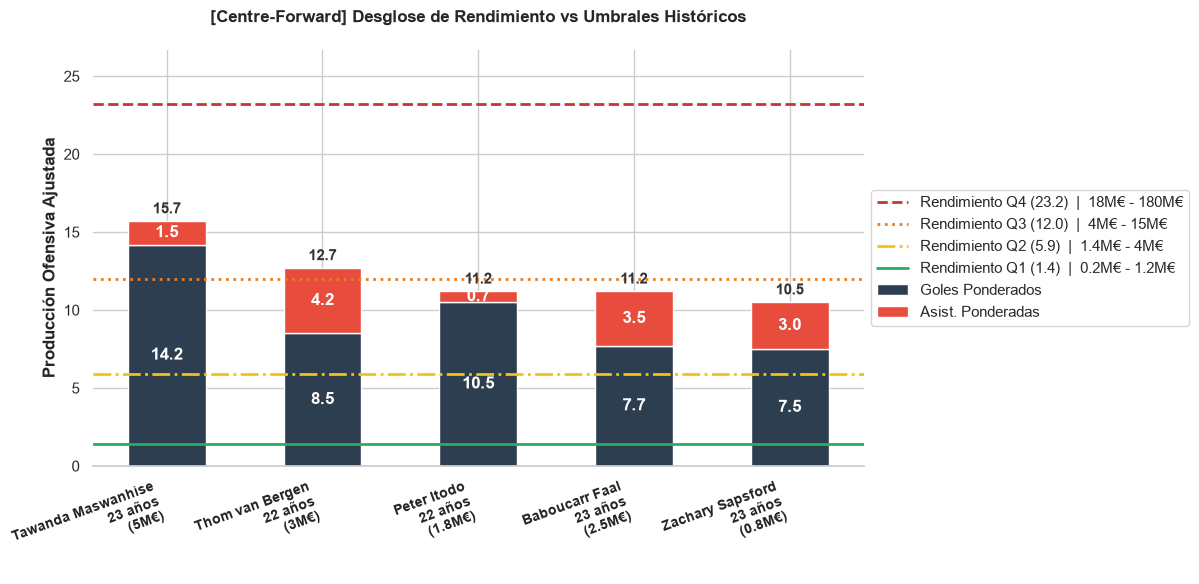

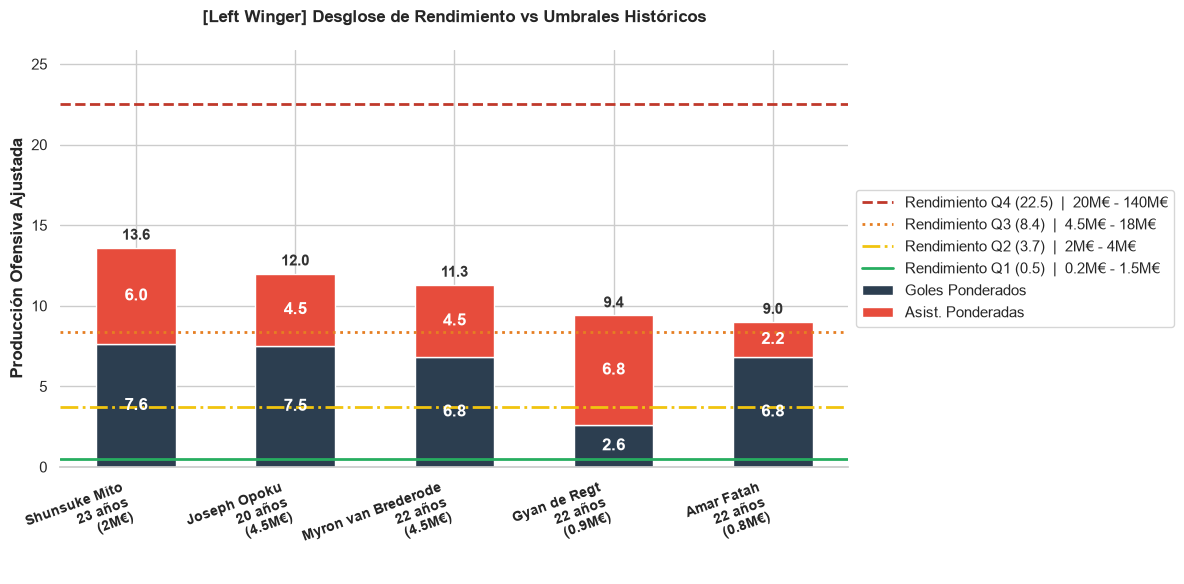

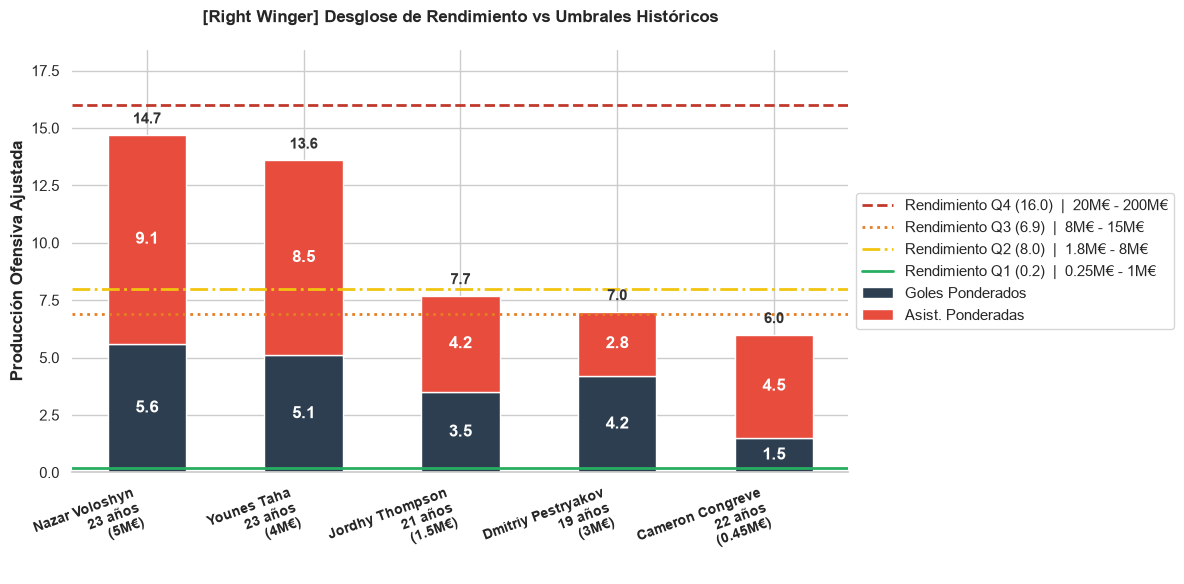

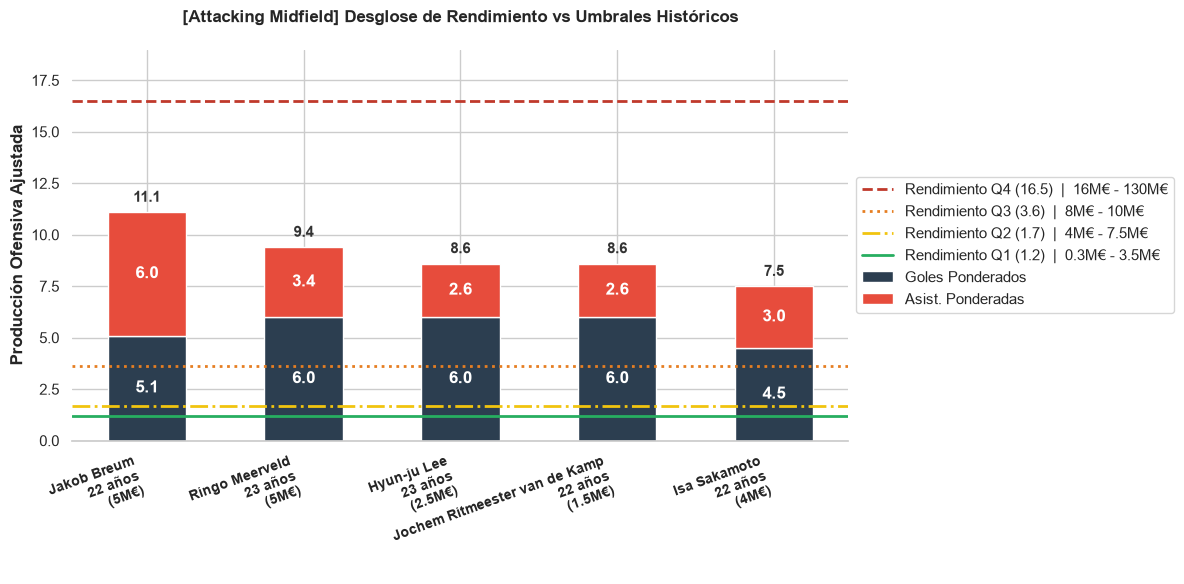

In [7]:
for demarcacion in demarcaciones_ofensivas:
    
    display(HTML(f"<h2 style='color:#2c3e50; border-bottom: 2px solid #2c3e50; margin-top: 40px; padding-bottom:5px;'>Análisis de Mercado: {demarcacion}</h2>"))
    
    # SOLO CLUBES HISTÓRICOS ININTERRUMPIDOS
    laliga_pos = df_1[(df_1['liga'] == liga_objetivo) & 
                      (df_1['sub_posicion'] == demarcacion) & 
                      (df_1['club'].isin(clubes_historicos_laliga))].copy()
    
    if laliga_pos.empty:
        print(f"No hay suficientes datos en La Liga para la posición {demarcacion}.")
        continue
        
    laliga_pos['produccion_total'] = laliga_pos['goles_25_26'] + laliga_pos['asis_25_26']
    
    # Dividir en 4 Cuartiles por PRECIO dinámicamente 
    etiquetas_cuartiles = ['Q1 (Bajo Coste)', 'Q2 (Media-Baja)', 'Q3 (Media-Alta)', 'Q4 (Élite)']
    laliga_pos['Cuartil_Mercado'] = pd.qcut(laliga_pos['valor_mercado'].rank(method='first'), q=4, labels=etiquetas_cuartiles)
    
    # Extraer Rangos de Precio y Estadísticas Medias 
    resumen_cuartiles = laliga_pos.groupby('Cuartil_Mercado', observed=False).agg(
        Precio_Min=('valor_mercado', 'min'),
        Precio_Max=('valor_mercado', 'max'),
        Goles_Media=('goles_25_26', 'mean'),
        Asis_Media=('asis_25_26', 'mean'),
        Prod_Media=('produccion_total', 'mean')
    ).reset_index()
    
    resumen_cuartiles['Rango Precio'] = resumen_cuartiles.apply(lambda x: f"{x['Precio_Min']/1e6:g}M€ - {x['Precio_Max']/1e6:g}M€", axis=1)
    resumen_cuartiles[['Goles_Media', 'Asis_Media', 'Prod_Media']] = resumen_cuartiles[['Goles_Media', 'Asis_Media', 'Prod_Media']].round(1)

    
    #  Ubicar gangas en los Cuartiles
    talentos = df_shortlist[df_shortlist['Demarcación'] == demarcacion].copy()
    if talentos.empty:
        print(f"No se encontraron talentos Sub-23 viables en la posición {demarcacion} por debajo de 5M€.\n")
        continue
        
    # Extraemos las métricas medias y los rangos
    prod_q4 = resumen_cuartiles.loc[3, 'Prod_Media']
    prod_q3 = resumen_cuartiles.loc[2, 'Prod_Media']
    prod_q2 = resumen_cuartiles.loc[1, 'Prod_Media']
    prod_q1 = resumen_cuartiles.loc[0, 'Prod_Media']
    
    rango_q4 = resumen_cuartiles.loc[3, 'Rango Precio']
    rango_q3 = resumen_cuartiles.loc[2, 'Rango Precio']
    rango_q2 = resumen_cuartiles.loc[1, 'Rango Precio']
    rango_q1 = resumen_cuartiles.loc[0, 'Rango Precio']
    
    # ORDENAMIENTO INTELIGENTE
    umbrales = [
        (prod_q4, 'Rinde como Q4 Élite'),
        (prod_q3, 'Rinde como Q3 (Media-Alta)'),
        (prod_q2, 'Rinde como Q2 (Media-Baja)'),
        (prod_q1, 'Rinde como Q1 (Bajo Coste)')
    ]
    umbrales_ordenados = sorted(umbrales, key=lambda x: x[0], reverse=True)
    
    condiciones = [talentos['Produccion_Ajustada'] >= u[0] for u in umbrales_ordenados]
    etiquetas_rendimiento = [u[1] for u in umbrales_ordenados]
    
    talentos['Rendimiento_Equivalente'] = np.select(condiciones, etiquetas_rendimiento, default='Bajo nivel')
    
    top_gangas = talentos.sort_values(by='Produccion_Ajustada', ascending=False).head(5)
    
    # Barras Apiladas con Rangos
    fig, ax = plt.subplots(figsize=(12, 6)) #ANCHURA AUMENTADA PARA QUE RESPIRE
    x = np.arange(len(top_gangas))
    
    barras_goles = ax.bar(x, top_gangas['Goles_Ajustados'], width=0.5, color='#2c3e50', label='Goles Ponderados')
    barras_asis = ax.bar(x, top_gangas['Asist_Ajustadas'], width=0.5, bottom=top_gangas['Goles_Ajustados'], color='#e74c3c', label='Asist. Ponderadas')
    
    ax.axhline(y=prod_q4, color='#c0392b', linestyle='--', linewidth=2, label=f'Rendimiento Q4 ({prod_q4})  |  {rango_q4}')
    ax.axhline(y=prod_q3, color='#e67e22', linestyle=':', linewidth=2, label=f'Rendimiento Q3 ({prod_q3})  |  {rango_q3}')
    ax.axhline(y=prod_q2, color='#f1c40f', linestyle='-.', linewidth=2, label=f'Rendimiento Q2 ({prod_q2})  |  {rango_q2}')
    ax.axhline(y=prod_q1, color='#27ae60', linestyle='-', linewidth=2, label=f'Rendimiento Q1 ({prod_q1})  |  {rango_q1}')
    
    ax.set_ylabel('Producción Ofensiva Ajustada', fontweight='bold')
    ax.set_title(f'[{demarcacion}] Desglose de Rendimiento vs Umbrales Históricos', fontweight='bold', pad=20)
    ax.set_xticks(x)
    #Evitar solapamientos nombres
    
    # Creamos una lista combinando el Nombre y el Valor de Mercado (en millones)
    etiquetas_x = [f"{nombre}\n{int(edad)} años\n({precio/1e6:g}M€)" for nombre,edad, precio in zip(top_gangas['Nombre'], top_gangas['Edad'], top_gangas['Valor Mercado (€)'])]
    
    #Asignamos la nueva lista al eje X
    ax.set_xticklabels(etiquetas_x, fontsize=10, fontweight='bold', rotation=20, ha='right')    
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    
    ax.bar_label(barras_goles, fmt=lambda val: f'{val:.1f}' if val > 0 else '', label_type='center', color='white', fontweight='bold')
    ax.bar_label(barras_asis, fmt=lambda val: f'{val:.1f}' if val > 0 else '', label_type='center', color='white', fontweight='bold')
    
    for i, total in enumerate(top_gangas['Produccion_Ajustada']):
        ax.text(i, total + 0.5, f"{total:.1f}", ha='center', fontweight='bold', color='#333333', fontsize=11)
    
    limite_superior = max(top_gangas['Produccion_Ajustada'].max(), umbrales_ordenados[0][0])
    ax.set_ylim(0, limite_superior + (limite_superior * 0.15))
    
    sns.despine(left=True)
    plt.tight_layout()
    plt.show()